In [ ]:
%cd /content
!rm -rf /content/work /content/for_vedant*.zip
from google.colab import files
up = files.upload()   # choose the NEWEST for_vedant.zip from Rahul
print(list(up.keys()))

/content


Saving for_vedant.zip to for_vedant.zip
['for_vedant.zip']


In [ ]:
zipname = list(up.keys())[0]
!mkdir -p /content/work
!unzip -o "{zipname}" -d /content/work
%cd /content/work
!ls

Archive:  for_vedant.zip
   creating: /content/work/rahul_5fold_outputs/
  inflating: /content/work/rahul_5fold_outputs/runs.csv  
  inflating: /content/work/rahul_5fold_outputs/config.json  
   creating: /content/work/rahul_5fold_outputs/history/
  inflating: /content/work/rahul_5fold_outputs/history/DWUNet_fold1_seed0.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold4_seed2.csv  
  inflating: /content/work/rahul_5fold_outputs/history/DWUNet_fold1_seed1.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold4_seed0.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold4_seed1.csv  
  inflating: /content/work/rahul_5fold_outputs/history/DWUNet_fold1_seed2.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold2_seed2.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold2_seed1.csv  
  inflating: /content/work/rahul_5fold_outputs/history/UNet_fold2_seed0.csv  
  inflating: /content/work/rahul_5fold_outpu

In [ ]:
import os, pandas as pd
r = pd.read_csv("rahul_5fold_outputs/runs.csv")
print(len(r), "runs"); print(r.groupby("model").size())
v = pd.read_csv("rahul_v3_outputs/v3_tiles.csv")
print(v.tile.nunique(), "tiles,", len(v), "rows")
ex = "rahul_v3_outputs/extra_methods_vs_hand.csv"
print("your method's scores present:", os.path.exists(ex))
if os.path.exists(ex):
    print(pd.read_csv(ex).model.unique())

45 runs
model
DWAttUNet    15
DWUNet       15
UNet         15
dtype: int64
8 tiles, 360 rows
your method's scores present: True
['DoG']


In [ ]:
!python vedant_all.py

Wrote slides_assets/summary.md
Zipped to slides_assets.zip

# Results summary (auto-generated by vedant_all.py)

## 1. 5-fold cross-validation (test tiles with pseudo-label ground truth)

5 folds x 3 seeds = 15 runs per model. Mean ± std over all runs:

| model | dice | iou | f1 | aji | ap50 |
|---|---|---|---|---|---|
| UNet | 0.778 ± 0.016 | 0.825 ± 0.012 | 0.715 ± 0.015 | 0.539 ± 0.014 | 0.569 ± 0.029 |
| DWUNet | 0.767 ± 0.022 | 0.816 ± 0.015 | 0.688 ± 0.030 | 0.537 ± 0.024 | 0.567 ± 0.043 |
| DWAttUNet | 0.769 ± 0.019 | 0.817 ± 0.015 | 0.690 ± 0.014 | 0.532 ± 0.018 | 0.554 ± 0.036 |

Best mean per metric: dice: UNet (0.778); iou: UNet (0.825); f1: UNet (0.715); aji: UNet (0.539); ap50: UNet (0.569)

- 5-fold CV: after Holm correction **no pairwise difference is significant (p < 0.05)** in any of the 5 metrics (5 paired units per model).
- Friedman test is significant for: f1 (p=0.015).

Pairwise paired t-tests on per-fold means (seeds averaged), Holm-corrected:

| metric | model_a

5-fold results (pseudo-label ground truth):


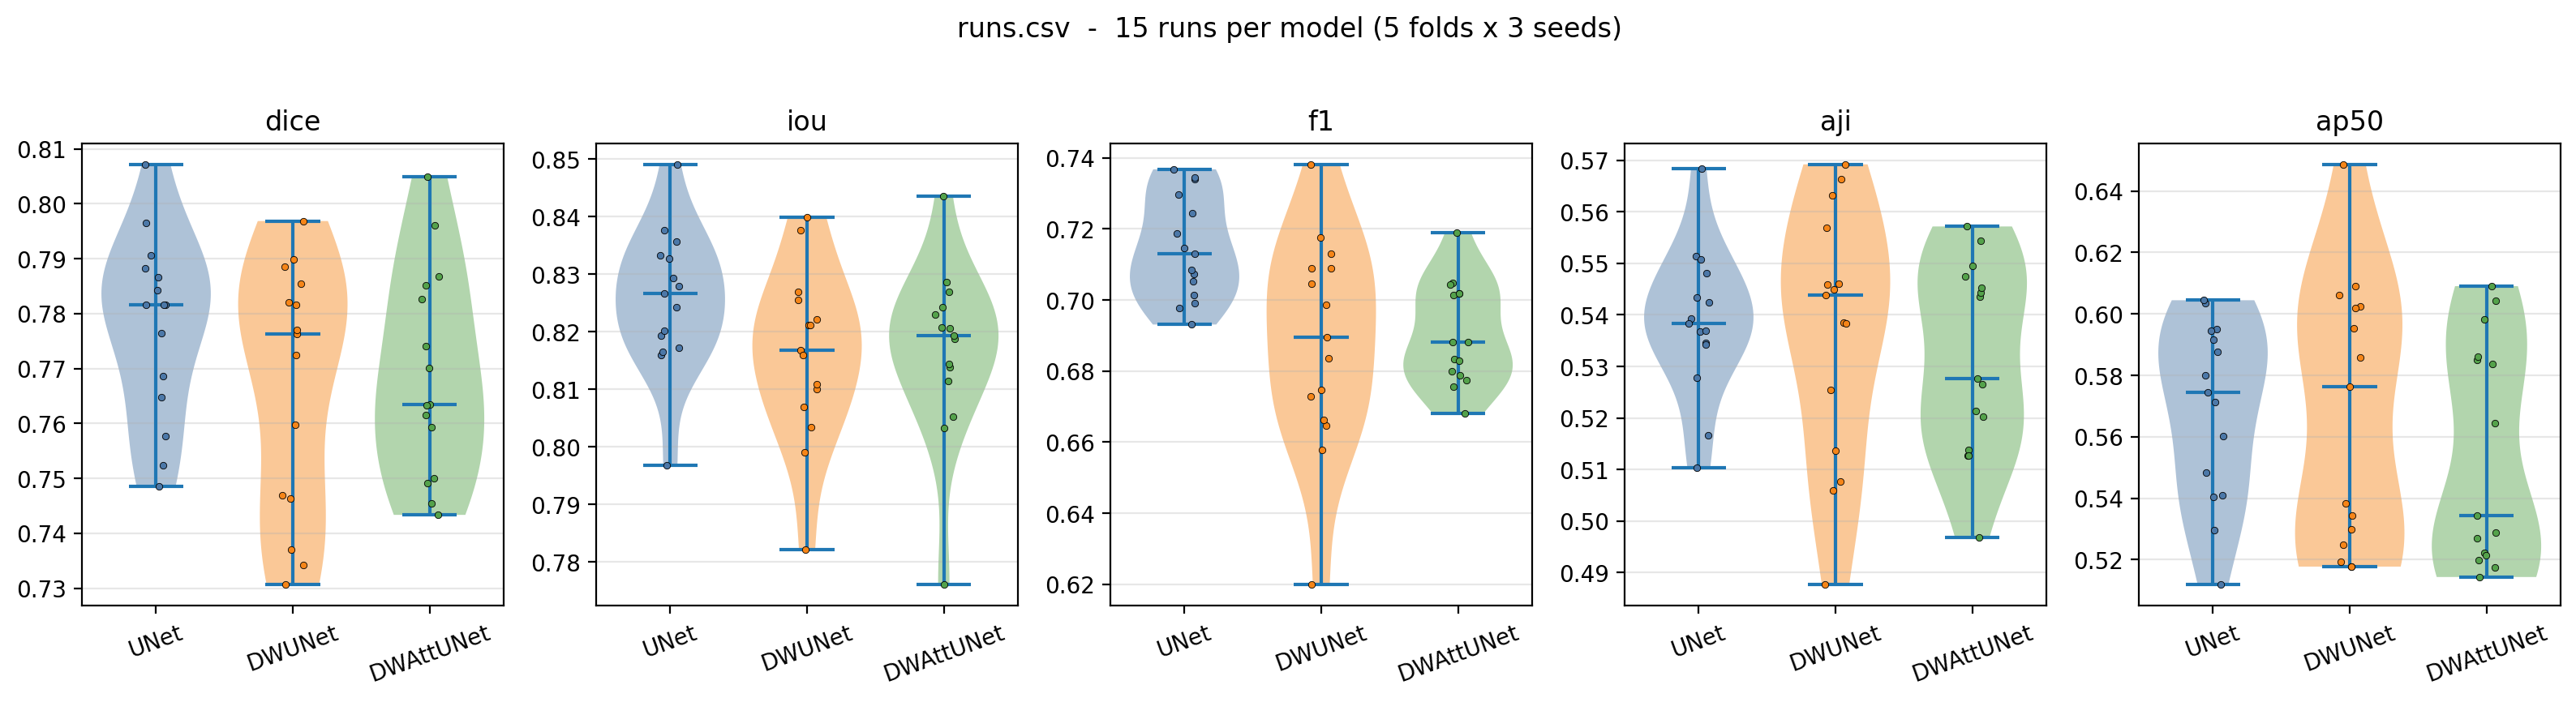

Video-3 results (hand-label ground truth):


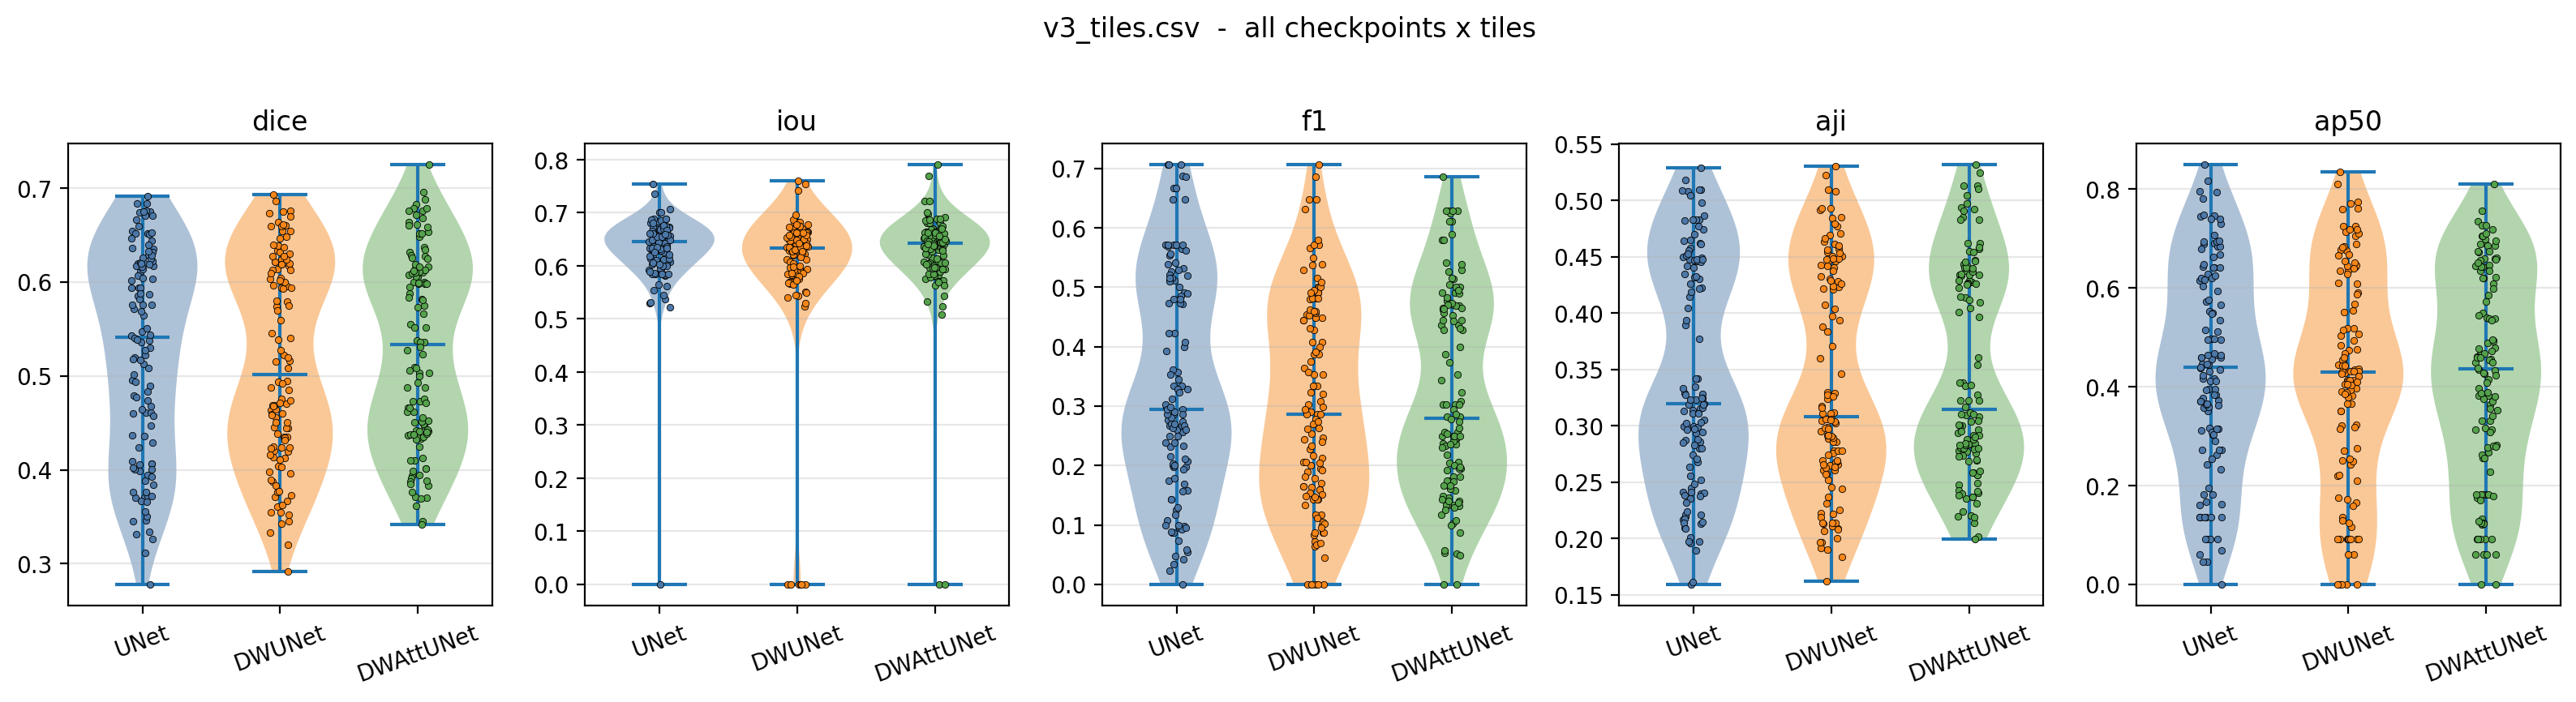

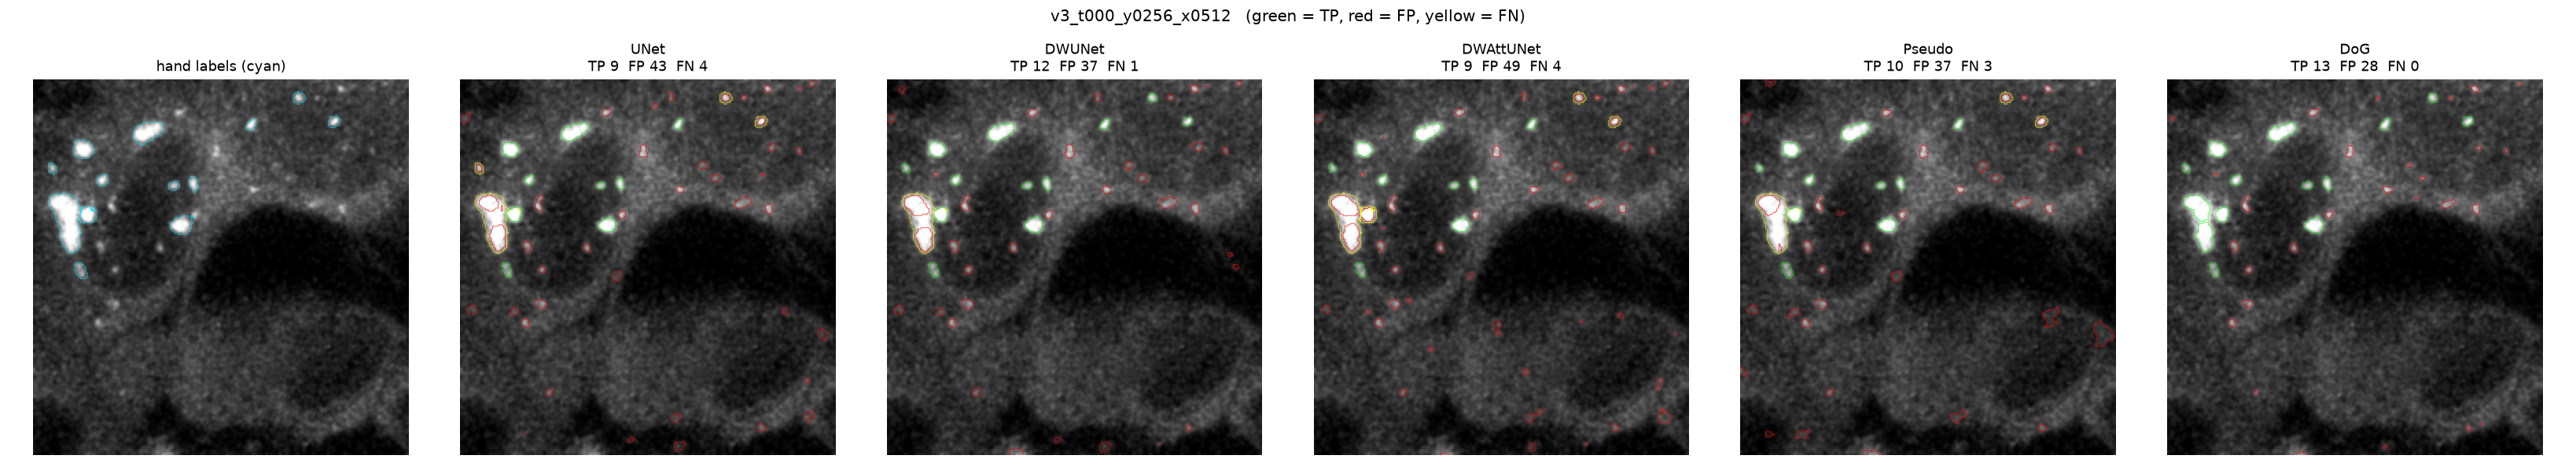

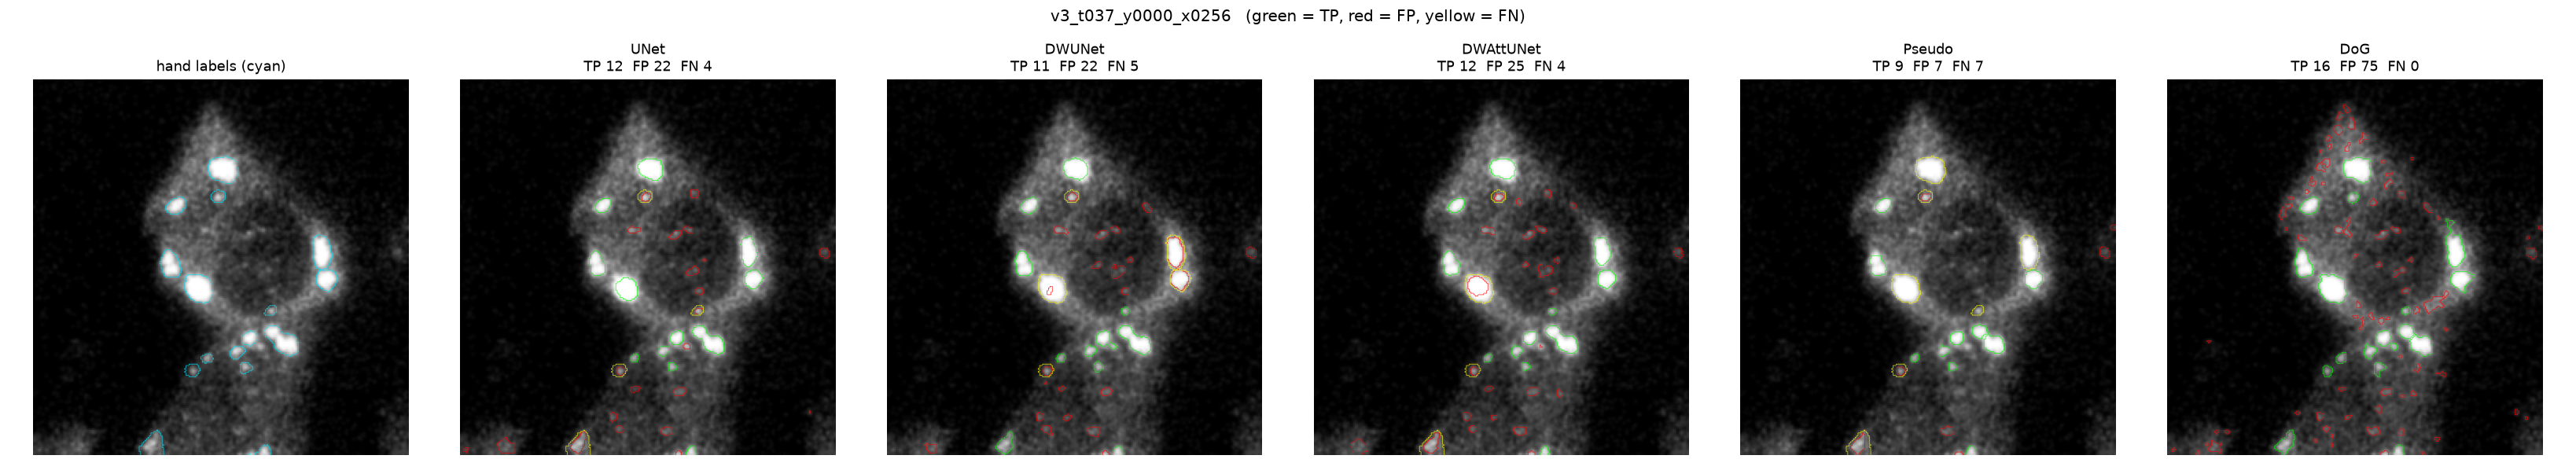

In [ ]:
from IPython.display import Image, display
import glob
print("5-fold results (pseudo-label ground truth):")
display(Image("slides_assets/stats_folds/violins.png"))
print("Video-3 results (hand-label ground truth):")
display(Image("slides_assets/stats_video3/violins.png"))
for f in sorted(glob.glob("slides_assets/overlays/*.png"))[:2]:
    display(Image(f))

In [ ]:
from IPython.display import Markdown, display
display(Markdown(open("slides_assets/summary.md").read()))

# Results summary (auto-generated by vedant_all.py)

## 1. 5-fold cross-validation (test tiles with pseudo-label ground truth)

5 folds x 3 seeds = 15 runs per model. Mean ± std over all runs:

| model | dice | iou | f1 | aji | ap50 |
|---|---|---|---|---|---|
| UNet | 0.778 ± 0.016 | 0.825 ± 0.012 | 0.715 ± 0.015 | 0.539 ± 0.014 | 0.569 ± 0.029 |
| DWUNet | 0.767 ± 0.022 | 0.816 ± 0.015 | 0.688 ± 0.030 | 0.537 ± 0.024 | 0.567 ± 0.043 |
| DWAttUNet | 0.769 ± 0.019 | 0.817 ± 0.015 | 0.690 ± 0.014 | 0.532 ± 0.018 | 0.554 ± 0.036 |

Best mean per metric: dice: UNet (0.778); iou: UNet (0.825); f1: UNet (0.715); aji: UNet (0.539); ap50: UNet (0.569)

- 5-fold CV: after Holm correction **no pairwise difference is significant (p < 0.05)** in any of the 5 metrics (5 paired units per model).
- Friedman test is significant for: f1 (p=0.015).

Pairwise paired t-tests on per-fold means (seeds averaged), Holm-corrected:

| metric | model_a | model_b | mean_diff_a_minus_b | p_raw | p_holm | cohens_dz |
|---|---|---|---|---|---|---|
| dice | UNet | DWUNet | 0.011 | 0.032 | 0.097 | 1.439 |
| dice | UNet | DWAttUNet | 0.009 | 0.124 | 0.248 | 0.868 |
| dice | DWUNet | DWAttUNet | -0.002 | 0.646 | 0.646 | -0.222 |
| iou | UNet | DWUNet | 0.009 | 0.062 | 0.185 | 1.151 |
| iou | UNet | DWAttUNet | 0.009 | 0.186 | 0.371 | 0.714 |
| iou | DWUNet | DWAttUNet | -0.001 | 0.905 | 0.905 | -0.057 |
| f1 | UNet | DWUNet | 0.027 | 0.034 | 0.071 | 1.419 |
| f1 | UNet | DWAttUNet | 0.024 | 0.024 | 0.071 | 1.589 |
| f1 | DWUNet | DWAttUNet | -0.002 | 0.785 | 0.785 | -0.130 |
| aji | UNet | DWUNet | 0.002 | 0.813 | 0.900 | 0.113 |
| aji | UNet | DWAttUNet | 0.007 | 0.273 | 0.820 | 0.567 |
| aji | DWUNet | DWAttUNet | 0.005 | 0.450 | 0.900 | 0.374 |
| ap50 | UNet | DWUNet | 0.002 | 0.877 | 0.980 | 0.074 |
| ap50 | UNet | DWAttUNet | 0.015 | 0.205 | 0.614 | 0.677 |
| ap50 | DWUNet | DWAttUNet | 0.013 | 0.490 | 0.980 | 0.339 |

## 2. Video-3 (HAND-labelled ground truth, 8 tiles)

Mean ± std over all (checkpoint, tile) scores:

| model | dice | iou | f1 | aji | ap50 |
|---|---|---|---|---|---|
| UNet | 0.526 ± 0.110 | 0.633 ± 0.072 | 0.335 ± 0.187 | 0.344 ± 0.101 | 0.437 ± 0.210 |
| DWUNet | 0.515 ± 0.107 | 0.599 ± 0.144 | 0.302 ± 0.177 | 0.339 ± 0.099 | 0.416 ± 0.222 |
| DWAttUNet | 0.529 ± 0.101 | 0.627 ± 0.093 | 0.319 ± 0.170 | 0.349 ± 0.093 | 0.423 ± 0.211 |

Best mean per metric: dice: DWAttUNet (0.529); iou: UNet (0.633); f1: UNet (0.335); aji: DWAttUNet (0.349); ap50: UNet (0.437)

Granule counts summed over the tiles (mean over 15 checkpoints) and precision / recall:

| model | tp | fp | fn | precision | recall |
|---|---|---|---|---|---|
| DWAttUNet | 74.300 | 275.500 | 27.700 | 0.212 | 0.728 |
| DWUNet | 72.900 | 279.600 | 29.100 | 0.207 | 0.715 |
| UNet | 74.600 | 250.700 | 27.400 | 0.229 | 0.731 |

- Video-3: pairs significant after Holm correction (p < 0.05), 8 paired units:
  - f1: UNet > DWUNet (diff 0.033, p_holm 0.0203, dz 1.34)
- Friedman test is significant for: dice (p=0.021), iou (p=0.021), f1 (p=0.021).

Only 8 tiles: p-values here have little power, treat as indicative.

Pairwise paired t-tests per tile (checkpoints averaged), Holm-corrected:

| metric | model_a | model_b | mean_diff_a_minus_b | p_raw | p_holm | cohens_dz |
|---|---|---|---|---|---|---|
| dice | UNet | DWUNet | 0.011 | 0.323 | 0.646 | 0.376 |
| dice | UNet | DWAttUNet | -0.003 | 0.769 | 0.769 | -0.108 |
| dice | DWUNet | DWAttUNet | -0.014 | 0.044 | 0.133 | -0.865 |
| iou | UNet | DWUNet | 0.034 | 0.194 | 0.501 | 0.507 |
| iou | UNet | DWAttUNet | 0.005 | 0.413 | 0.501 | 0.307 |
| iou | DWUNet | DWAttUNet | -0.029 | 0.167 | 0.501 | -0.545 |
| f1 | UNet | DWUNet | 0.033 | 0.007 | 0.020 | 1.341 |
| f1 | UNet | DWAttUNet | 0.016 | 0.182 | 0.182 | 0.524 |
| f1 | DWUNet | DWAttUNet | -0.017 | 0.085 | 0.170 | -0.709 |
| aji | UNet | DWUNet | 0.005 | 0.502 | 1.000 | 0.250 |
| aji | UNet | DWAttUNet | -0.005 | 0.628 | 1.000 | -0.179 |
| aji | DWUNet | DWAttUNet | -0.010 | 0.097 | 0.292 | -0.676 |
| ap50 | UNet | DWUNet | 0.020 | 0.186 | 0.559 | 0.518 |
| ap50 | UNet | DWAttUNet | 0.013 | 0.326 | 0.652 | 0.373 |
| ap50 | DWUNet | DWAttUNet | -0.007 | 0.598 | 0.652 | -0.195 |

## 3. Model size and speed (5-fold runs, MacBook Air M3 GPU)

| model | params | epochs | train_minutes | tiles_per_s | precision | recall | loc_err | size_vs_UNet |
|---|---|---|---|---|---|---|---|---|
| UNet | 1943761 | 21.733 | 12.578 | 108.431 | 0.717 | 0.715 | 0.594 | 1.000 |
| DWUNet | 389435 | 22.667 | 13.308 | 117.665 | 0.687 | 0.691 | 0.607 | 0.200 |
| DWAttUNet | 411559 | 24.067 | 15.277 | 106.538 | 0.692 | 0.690 | 0.617 | 0.210 |

## 4. How good are the pseudo-labels? (classical labeller scored against the hand labels)

Mean over tiles: dice 0.471, iou 0.550, f1 0.381, aji 0.310, ap50 0.353. Granule counts: TP 65, FP 130, FN 37 (precision 0.33, recall 0.64).

## 4b. Every approach on the hand-labelled tiles (human labels = ground truth)

Trained networks: mean over their 15 checkpoints. Pseudo-labeller and label-free methods: a single deterministic run each (no seeds/folds), so no p-values for them. Scores are means over the tiles, counts are summed over the tiles.

| model | dice | iou | f1 | aji | ap50 | tp | fp | fn | precision | recall |
|---|---|---|---|---|---|---|---|---|---|---|
| DWAttUNet | 0.529 | 0.627 | 0.319 | 0.349 | 0.423 | 74.333 | 275.533 | 27.667 | 0.212 | 0.729 |
| DWUNet | 0.515 | 0.599 | 0.302 | 0.339 | 0.416 | 72.933 | 279.600 | 29.067 | 0.207 | 0.715 |
| UNet | 0.526 | 0.633 | 0.335 | 0.344 | 0.437 | 74.600 | 250.733 | 27.400 | 0.229 | 0.731 |
| DoG | 0.502 | 0.704 | 0.224 | 0.335 | 0.560 | 81.000 | 714.000 | 21.000 | 0.102 | 0.794 |
| Pseudo | 0.471 | 0.550 | 0.381 | 0.310 | 0.353 | 65.000 | 130.000 | 37.000 | 0.333 | 0.637 |

## 5. Caveats to state on the slides

- 5-fold ground truth is the classical pseudo-labeller, not human annotation: scores measure agreement with it.
- Only 5 folds: the smallest possible Wilcoxon p-value is 0.0625, so tests use paired t-tests on per-fold means with Holm correction.
- The 3 seeds in a fold are not independent samples, so seeds are averaged before testing; violins still show all runs.
- Video-3 hand labels cover a small number of tiles and one annotator.
- Instances come from connected components of a binary mask, so touching granules are merged into one.


In [ ]:
from google.colab import files
files.download("slides_assets.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>